# Does "beta initialization" really help quantum neural networks?

A reproduction of Herbst, De Maio and Brandic, *On Optimizing Hyperparameters
for Quantum Neural Networks* (IEEE QCE 2024,
[arXiv:2403.18579](https://arxiv.org/abs/2403.18579)), with a photonic
(MerLin) adaptation and a fair classical comparison.

**How to read this notebook.** Each section asks one question, shows the
evidence, and ends with an *Observation / Inference / Remaining uncertainty /
Claim impact* block. Cells marked **LIVE** run here on a CPU (the whole
notebook takes about 5 minutes). Cells marked **STORED** load results from the
full sweeps, which ran on a GPU server (`merlin-ai`: 8 vCPU, NVIDIA L4). Their
provenance is given in the cell. The full record is in `LOG.md` and `README.md`.

**Verdict up front.** The released numbers reproduce. The paper's main claim,
that a beta-distribution initialization is better, does not. The author code
never applies the initialization. What the "beta" arms actually do differently
is rescale the inputs to [0, 1], and that rescaling explains the whole effect.

| Section | Content |
|---|---|
| 1 | Problem statement and the claim under test |
| 2 | Data, splits, metrics and evaluation protocol |
| 3 | Minimum mathematics: angle encoding, the VQC loss, the initialization |
| 4 | Known-answer sanity checks |
| 5 | Model and pipeline walkthrough |
| 6 | Live experiment: scaling vs applied initialization |
| 7 | Headline reproduction: the released results and the faithful re-runs |
| 8 | Fair baseline comparison |
| 9 | Controls and ablations |
| 10 | Robustness and uncertainty |
| 11 | Photonic (MerLin) adaptation |
| 12 | Claim-level conclusion and limitations |

In [1]:
# Setup: paths, imports from lib/, and the environment this notebook ran in.
import copy
import json
import platform
import subprocess
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

PAPER_DIR = Path.cwd()
if not (PAPER_DIR / "lib" / "runner.py").exists():
    raise RuntimeError("Run this notebook from papers/QNN_hyperparameters/")
sys.path.insert(0, str(PAPER_DIR.parent))
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.exceptions import ConvergenceWarning
# The Phase 1 MLP budget is a fixed 500 epochs; sklearn warns when it is reached.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from QNN_hyperparameters.lib import reanalysis
from QNN_hyperparameters.lib.baselines import fit_and_evaluate
from QNN_hyperparameters.lib.circuits import build_ansatz, build_feature_map, paper_grid
from QNN_hyperparameters.lib.data import prepare_data
from QNN_hyperparameters.lib.qnn import QNNClassifier, initial_point
from QNN_hyperparameters.lib.simulator import CompiledCircuit

RESULTS = PAPER_DIR / "results"
DATA_ROOT = (PAPER_DIR / ".." / ".." / "data").resolve()
RELEASED = DATA_ROOT / "QNN_hyperparameters" / "sources" / "author_repo" / "reports" / "results"
BASE_CONFIG = json.loads((PAPER_DIR / "configs" / "defaults.json").read_text())
BASE_CONFIG["data_root"] = str(DATA_ROOT)

# One colour per system and per input scaling, used in every figure.
COLORS = {"qubit": "#2a78d6", "classical": "#eb6834", "photonic": "#1baf7a"}
SCALING_COLORS = {"raw": "#eb6834", "minmax": "#2a78d6"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e6e5e0"})

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
import merlin, qiskit, sklearn, torch
print(f"code revision {commit} | python {platform.python_version()} | {platform.processor() or platform.machine()}")
print(f"qiskit {qiskit.__version__} | scikit-learn {sklearn.__version__} | torch {torch.__version__} | merlin {merlin.__version__}")
print("device for live cells: cpu")
NOTEBOOK_START = time.time()

code revision 43ff7fb | python 3.12.10 | Intel64 Family 6 Model 181 Stepping 0, GenuineIntel
qiskit 1.4.6 | scikit-learn 1.9.1 | torch 2.12.1+cpu | merlin 0.4.1
device for live cells: cpu


## 1. Problem statement and the claim under test

The paper trains Qiskit variational quantum classifiers (a *feature map* that
encodes the data, then a trainable *ansatz*, then a measurement) on four tabular
UCI datasets, and sweeps the hyperparameters: feature map, ansatz, entanglement,
optimizer and the **initialization of the trainable parameters**.

The paper's main findings:
- **C1:** a beta-distribution initialization (BEINIT) is significantly better
  than uniform and normal initialization "in all settings".
- **C2:** SPSA and COBYLA beat Nelder-Mead, and COBYLA is faster.
- **C3:** beta, constant-at-the-beta-mean, and normal-with-beta-moments
  initializations do not differ. The paper reads this as "the value range, not
  the distribution, matters".

**Falsifiable research question.** *With everything else held fixed, does
starting the optimizer from a beta-distributed parameter vector raise
validation accuracy?*

**What would weaken C1:**
1. the initialization never reaches the optimizer;
2. the "beta" arms differ from the others in something other than the
   initialization;
3. holding that other difference fixed, an *applied* beta initialization gives
   no gain.

This notebook finds all three (sections 3, 4, 6 and 9).

## 2. Data, splits, metrics and evaluation protocol

The data pipeline follows the author code exactly (`lib/data.py`):
1. A stratified 60/20/20 train/validation/test split (`random_state=5`).
2. PCA to 7 components on standardized features, or LDA to `min(7, n_classes-1)`
   components on raw features, fit on the training split.
3. A subsample of 400 training and 250 validation rows (`random_state=12`).
   Glass has only 214 rows, so its splits are 128/43/43.
4. **Optionally, MinMax scaling to [0, 1], fit on the training rows.** In the
   author code this happens only in the "beta"-family arms.

**Metric:** accuracy (and weighted F1) on the 250 validation rows, as in the
paper. The paper uses the same rows to choose its "top" configurations, so its
reported maxima are optimistic.

**Our protocol.** We never use the test split to choose anything. Test accuracy
is reported only for configurations already chosen on validation (section 8).

The cell below builds Rice (the dataset most of this notebook uses) both ways.

In [2]:
# LIVE: prepare Rice exactly as the author pipeline does, raw and MinMax.
def rice_config(scaling, **overrides):
    cfg = copy.deepcopy(BASE_CONFIG)
    cfg["dataset"]["input_scaling"] = scaling
    for key, value in overrides.items():
        cfg[key].update(value)
    return cfg

rice = {scaling: prepare_data(rice_config(scaling)) for scaling in ("raw", "minmax")}
summary = pd.DataFrame(
    {
        scaling: {
            "features (= qubits)": data.n_features,
            "train / val / test rows": " / ".join(str(len(data.y[s])) for s in ("train", "val", "test")),
            "train feature min": data.X["train"].min().round(2),
            "train feature max": data.X["train"].max().round(2),
            "val feature min": data.X["val"].min().round(2),
            "val feature max": data.X["val"].max().round(2),
            "class balance (train)": np.round(np.mean(data.y["train"] == data.y["train"].max()), 3),
        }
        for scaling, data in rice.items()
    }
)
summary

,raw,minmax
features (= qubits),7,7
train / val / test rows,400 / 250 / 250,400 / 250 / 250
train feature min,-5.64,0.0
train feature max,5.48,1.0
val feature min,-4.55,-0.39
val feature max,5.45,1.12
class balance (train),0.575,0.575


**Observation.** The two variants have the same rows, labels and 7 features.
The only difference is the range: raw PCA scores span about [-5.6, 5.5] on the
training rows, while MinMax features span [0, 1]. Validation can fall slightly outside
[0, 1], because the scaler is fit on training rows only, which is correct (no
leakage).

**Inference.** If the "beta" arm sees MinMax inputs and the other arms see raw
inputs, any accuracy gap between them mixes two causes: the initialization and
the input range.

**Remaining uncertainty.** Whether that mixing actually happens in the author
code (section 3), and how large each cause is (section 6).

**Claim impact.** None yet. This section sets up the protocol.

## 3. Minimum mathematics

**Angle encoding.** The `ZFeatureMap` applies a Hadamard and then a phase gate
$P(2x_i)$ on qubit $i$, repeated twice. A feature enters as an angle
$\phi_i = 2x_i$, which matters only modulo $2\pi$. With raw Rice features
$x_i \in [-5.6, 5.5]$, $\phi_i$ sweeps about $[-11, 11]$ rad: almost four full
turns. Inputs that are far apart in feature space can then land on nearly the
same quantum state, and the classifier cannot separate them. With MinMax
features, $\phi_i \in [0, 2]$ rad: no wrap-around at all.

**Model and loss.** The ansatz $U(\theta)$ (e.g. `RealAmplitudes`, 28
parameters on 7 qubits) acts on the encoded state. A measured bitstring $b$ is
mapped to class $\mathrm{int}(b) \bmod K$ (qiskit-ml's VQC readout). Training
minimises the cross-entropy $-\frac{1}{N}\sum_n \log_2 p_\theta(y_n \mid x_n)$,
estimated from 1024 shots per sample, with a gradient-free optimizer (COBYLA,
SPSA or Nelder-Mead).

**The initialization (BEINIT).** Fit a beta distribution
$\mathrm{Beta}(a, b)$ to the MinMax-scaled training features, then draw the
starting point $\theta_0 \sim \mathrm{Beta}(a, b)$.

**What the author code does.** In `src/util/opt.py` (author repository, lines
187-207, shown below), every initialization arm calls
`vqc.ansatz.assign_parameters(...)` and **discards the result**. In Qiskit,
`assign_parameters` returns a *new* circuit and leaves the original unchanged.
So the VQC still has all of its free parameters, receives no `initial_point`,
and starts from qiskit-ml's own default, $\mathcal{U}[0, 1)$, in every arm.
Lines 188-190 show that the beta arm also MinMax-scales `X_train` and `X_val`.

In [3]:
# Show the author code (cached copy of the released repository), lines 187-207.
author_opt = (DATA_ROOT / "QNN_hyperparameters" / "sources" / "author_repo" / "src" / "util" / "opt.py").read_text().splitlines()
print("\n".join(f"{number:4d}  {line}" for number, line in enumerate(author_opt, 1) if 187 <= number <= 207))

 187          if beta_init:
 188              scaler = MinMaxScaler()
 189              X_train_use = scaler.fit_transform(X_train_use)
 190              X_val_use = scaler.transform(X_val_use)
 191              vqc.ansatz.assign_parameters(self.init_beta(X_train_use, vqc.ansatz.num_parameters))
 192          elif normal_init:
 193              vqc.ansatz.assign_parameters(np.random.normal(loc=0.0, scale=np.sqrt(1/vqc.ansatz.num_layers), size=vqc.ansatz.num_parameters))
 194          elif zero_init:
 195              vqc.ansatz.assign_parameters(np.zeros(vqc.ansatz.num_parameters))
 196          elif normal_mu_sigma_init or beta_mu:
 197              scaler = MinMaxScaler()
 198              X_train_use = scaler.fit_transform(X_train_use)
 199              X_val_use = scaler.transform(X_val_use)
 200              a, b = self.init_beta(X_train_use, vqc.ansatz.num_parameters, get_params=True)
 201              # get mu and sd from beta distribution
 202              mu = a/(a+b)
 203    

## 4. Known-answer sanity checks

Before trusting any accuracy number, we check four things whose answers we know
in advance:
1. **`assign_parameters` does not modify the circuit in place.** If it did, the
   author's initialization would be applied, and section 3 would be wrong.
2. **Our fast simulator equals Qiskit's exact statevector** on the paper's
   circuits. The live runs below use it instead of Qiskit's sampler.
3. **Our initialization really reaches the optimizer.** Different `init`
   settings must give different starting losses.
4. **1024-shot sampling is unbiased.** Averaged over many draws, shot estimates
   must approach the exact probabilities.

In [4]:
# LIVE sanity check 1: Qiskit's assign_parameters returns a new circuit.
ansatz = build_ansatz("RealAmplitudes", 7, "linear", 3)
bound = ansatz.assign_parameters(np.zeros(ansatz.num_parameters))
print(f"original ansatz free parameters after the call: {ansatz.num_parameters}")
print(f"returned circuit free parameters:              {bound.num_parameters}")
assert ansatz.num_parameters == 28 and bound.num_parameters == 0
print("PASS: the call leaves the ansatz untouched, so the author's initialization is discarded.")

original ansatz free parameters after the call: 28
returned circuit free parameters:              0
PASS: the call leaves the ansatz untouched, so the author's initialization is discarded.


In [5]:
# LIVE sanity check 2: batched simulator vs Qiskit Statevector, on three of the paper's 84 circuits.
from qiskit.quantum_info import Statevector

worst = 0.0
for grid_index in (0, 31, 57):
    circuit = paper_grid()[grid_index]
    feature_map = build_feature_map(circuit["feature_map"], 7, circuit["feature_map_entanglement"])
    ansatz = build_ansatz(circuit["ansatz"], 7, circuit["ansatz_entanglement"])
    compiled = CompiledCircuit(feature_map, ansatz)
    rng = np.random.default_rng(grid_index)
    X = rng.uniform(-4, 4, (2, 7))
    weights = rng.uniform(-3, 3, compiled.num_weights)
    ours = compiled.probabilities(X, weights)
    reference_circuit = feature_map.compose(ansatz)
    for row in range(2):
        binding = dict(zip(feature_map.parameters, X[row])) | dict(zip(ansatz.parameters, weights))
        exact = Statevector(reference_circuit.assign_parameters(binding)).probabilities()
        worst = max(worst, np.abs(ours[row] - exact).max())
    print(f"circuit {grid_index:2d}: {circuit['feature_map']} + {circuit['ansatz']} ({circuit['ansatz_entanglement']})")
print(f"largest |probability difference| = {worst:.1e}")
assert worst < 1e-10
print("PASS")

circuit  0: ZFeatureMap + EfficientSU2 (full)
circuit 31: ZFeatureMap + RealAmplitudes (linear)


circuit 57: ZFeatureMap + TwoLocal (pairwise)
largest |probability difference| = 9.7e-17
PASS


In [6]:
# LIVE sanity checks 3 and 4: the initialization reaches the loss, and shot sampling is unbiased.
model_cfg = dict(BASE_CONFIG["model"])
data = rice["minmax"]
starting_losses = {}
for init in ("qiskit_default", "beta", "zeros"):
    rng = np.random.default_rng(1)
    model = QNNClassifier(model_cfg | {"init": init}, data.n_features, shots=None, rng=rng)
    model.classes = np.unique(data.y["train"])  # fit() normally sets the class labels
    start, _ = initial_point(init, model.num_weights, model_cfg["ansatz_reps"], data.X["train"], rng)
    start = rng.random(model.num_weights) if start is None else start
    probabilities = model.class_probabilities(data.X["train"], start)
    targets = (data.y["train"] == data.y["train"].max()).astype(int)
    starting_losses[init] = -np.mean(np.log2(np.clip(probabilities[np.arange(len(targets)), targets], 1e-10, 1)))
print({init: round(loss, 4) for init, loss in starting_losses.items()})
assert len({round(value, 6) for value in starting_losses.values()}) == 3
print("PASS: three initializations give three different starting losses.")

exact_model = QNNClassifier(model_cfg | {"init": "zeros"}, data.n_features, shots=None, rng=np.random.default_rng(0))
exact_model.classes = np.unique(data.y["train"])
weights = np.random.default_rng(2).uniform(0, 1, exact_model.num_weights)
exact = exact_model.class_probabilities(data.X["train"][:20], weights)
def shot_estimate(seed):
    sampler = QNNClassifier(model_cfg | {"init": "zeros"}, data.n_features, shots=1024, rng=np.random.default_rng(seed))
    sampler.classes = exact_model.classes
    return sampler.class_probabilities(data.X["train"][:20], weights)

shot_draws = np.mean([shot_estimate(seed) for seed in range(30)], axis=0)
print(f"max |mean of 30 x 1024-shot estimates - exact| = {np.abs(shot_draws - exact).max():.4f}")
print("(per-entry standard error is about 0.003; the largest of 40 entries is expected near 0.007)")
assert np.abs(shot_draws - exact).max() < 0.02
print("PASS")

{'qiskit_default': np.float64(1.6176), 'beta': np.float64(1.4836), 'zeros': np.float64(2.4273)}
PASS: three initializations give three different starting losses.


max |mean of 30 x 1024-shot estimates - exact| = 0.0067
(per-entry standard error is about 0.003; the largest of 40 entries is expected near 0.007)
PASS


**Observation.** All four checks pass:
- the Qiskit call does not modify the circuit;
- our simulator matches Qiskit to better than $10^{-10}$;
- different initializations give different starting losses;
- shot estimates are unbiased.

**Inference.** The author's initialization arms all start from the same
distribution, so any difference between them comes from elsewhere. Our
implementation, by contrast, does apply the initialization, so section 6 can
test it.

**Remaining uncertainty.** The checks validate components. They do not by
themselves show that training reproduces the paper's numbers (that is
section 7).

**Claim impact.** C1 is **weakened**: the mechanism the paper credits is never
executed in the code that produced its results.

## 5. Model and pipeline walkthrough

One QNN run:
1. `prepare_data(cfg)` gives the arrays (section 2).
2. `QNNClassifier(model_cfg, n_qubits, shots, rng)` builds the feature map and
   ansatz, and compiles them into the batched simulator.
3. `fit(X, y, training_cfg)` minimises the VQC cross-entropy with the optimizer
   from `training_cfg`, starting from `initial_point(init, ...)`.
4. `evaluate(X, y)` returns accuracy and weighted F1.

All scientifically important settings are visible in the configuration below.
It is the paper's default circuit: `ZFeatureMap` (2 reps) + `RealAmplitudes`
(linear, 3 reps), COBYLA (maxiter 500, tol 0.1) and 1024 shots.

In [7]:
print(json.dumps({key: BASE_CONFIG[key] for key in ("model", "training")}, indent=1))
demo = QNNClassifier(BASE_CONFIG["model"], 7, shots=1024, rng=np.random.default_rng(0))
print(f"trainable parameters: {demo.num_weights}; qubits: 7; classes are read as int(bitstring) mod 2")
print(demo.feature_map.compose(demo.ansatz).decompose().draw(output="text", fold=-1, idle_wires=False).single_string()[:1200], "...")

{
 "model": {
  "feature_map": "ZFeatureMap",
  "feature_map_entanglement": null,
  "feature_map_reps": 2,
  "ansatz": "RealAmplitudes",
  "ansatz_entanglement": "linear",
  "ansatz_reps": 3,
  "init": "qiskit_default"
 },
 "training": {
  "optimizer": "COBYLA",
  "maxiter": 500,
  "tol": 0.1,
  "maxfev": 1000,
  "shots": 1024,
  "steps": 200,
  "lr": 0.05
 }
}
trainable parameters: 28; qubits: 7; classes are read as int(bitstring) mod 2


     ┌───┐┌─────────────┐┌───┐┌─────────────┐┌──────────┐     ┌──────────┐                        ┌───────────┐                          ┌───────────┐                                                                 
q_0: ┤ H ├┤ P(2.0*x[0]) ├┤ H ├┤ P(2.0*x[0]) ├┤ Ry(θ[0]) ├──■──┤ Ry(θ[7]) ├─────────────────■──────┤ Ry(θ[14]) ├───────────────────■──────┤ Ry(θ[21]) ├─────────────────────────────────────────────────────────────────
     ├───┤├─────────────┤├───┤├─────────────┤├──────────┤┌─┴─┐└──────────┘┌──────────┐   ┌─┴─┐    └───────────┘┌───────────┐    ┌─┴─┐    └───────────┘┌───────────┐                                                    
q_1: ┤ H ├┤ P(2.0*x[1]) ├┤ H ├┤ P(2.0*x[1]) ├┤ Ry(θ[1]) ├┤ X ├─────■──────┤ Ry(θ[8]) ├───┤ X ├──────────■──────┤ Ry(θ[15]) ├────┤ X ├──────────■──────┤ Ry(θ[22]) ├────────────────────────────────────────────────────
     ├───┤├─────────────┤├───┤├─────────────┤├──────────┤└───┘   ┌─┴─┐    └──────────┘┌──┴───┴───┐    ┌─┴─┐    └───────────┘┌───┴───┴───

## 6. Live experiment: input scaling vs an applied initialization

This is a small version of the controlled factorial E-B, run live:
- **Data:** Rice, validation accuracy.
- **Model:** the default circuit, COBYLA, 1024 shots.
- **Input scaling:** raw or MinMax.
- **Initialization, actually applied:** `qiskit_default` (what every author arm
  really used), `beta` (BEINIT, applied) or `zeros`.
- **Seeds:** 3 per cell, so 2 x 3 x 3 = 18 runs, about 3 minutes on CPU.

**Decision rule** (the same as E-B):
- if MinMax beats raw at every initialization;
- and the initializations do not differ at a fixed scaling;

then the "beta initialization" effect is an input-scaling effect.

*Reduction:* the full E-B uses 4 circuits x 2 optimizers x 2 datasets (288
runs, section 9). This live version uses 1 circuit, 1 optimizer and 1 dataset.
It illustrates the effect; the stored E-B is the decisive evidence.

In [8]:
# LIVE: 18 QNN runs on CPU.
from qiskit_machine_learning.utils import algorithm_globals

live_rows = []
start_time = time.time()
for scaling in ("raw", "minmax"):
    data = rice[scaling]
    for init in ("qiskit_default", "beta", "zeros"):
        for seed in (1, 2, 3):
            algorithm_globals.random_seed = seed
            model = QNNClassifier(BASE_CONFIG["model"] | {"init": init}, data.n_features, 1024, np.random.default_rng(seed))
            result = model.fit(data.X["train"], data.y["train"], BASE_CONFIG["training"])
            live_rows.append({"scaling": scaling, "init": init, "seed": seed, "evaluations": result.evaluations,
                              "val_accuracy": model.evaluate(data.X["val"], data.y["val"])["accuracy"]})
live = pd.DataFrame(live_rows)
print(f"18 runs in {time.time() - start_time:.0f} s")
live.pivot_table(index=["init", "seed"], columns="scaling", values="val_accuracy").round(3)

18 runs in 340 s


scaling              minmax    raw
init           seed               
beta           1      0.868  0.480
               2      0.824  0.476
               3      0.876  0.532
qiskit_default 1      0.892  0.492
               2      0.900  0.460
               3      0.888  0.504
zeros          1      0.908  0.472
               2      0.900  0.512
               3      0.904  0.448

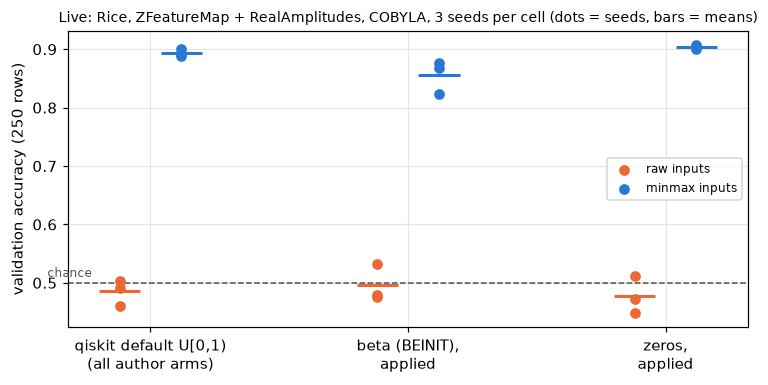

MinMax - raw, mean over seeds, per init: {'beta': 0.36, 'qiskit_default': 0.408, 'zeros': 0.427}
beta - default at fixed scaling, mean over seeds: {'minmax': -0.037, 'raw': 0.011}
zeros - default at fixed scaling, mean over seeds: {'minmax': 0.011, 'raw': -0.008}


In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6))
inits = ["qiskit_default", "beta", "zeros"]
for offset, scaling in ((-0.12, "raw"), (0.12, "minmax")):
    subset = live[live["scaling"] == scaling]
    for position, init in enumerate(inits):
        values = subset[subset["init"] == init]["val_accuracy"]
        ax.scatter(np.full(len(values), position + offset), values, color=SCALING_COLORS[scaling], s=36,
                   label=f"{scaling} inputs" if position == 0 else None, zorder=3)
        ax.hlines(values.mean(), position + offset - 0.08, position + offset + 0.08, color=SCALING_COLORS[scaling], lw=2)
ax.set_xticks(range(3), ["qiskit default U[0,1)\n(all author arms)", "beta (BEINIT),\napplied", "zeros,\napplied"])
ax.set_ylabel("validation accuracy (250 rows)")
ax.set_title("Live: Rice, ZFeatureMap + RealAmplitudes, COBYLA, 3 seeds per cell (dots = seeds, bars = means)", fontsize=9)
ax.axhline(0.5, color="#52514e", ls="--", lw=1)
ax.text(-0.4, 0.51, "chance", fontsize=8, color="#52514e")
ax.legend(loc="center right", fontsize=8)
plt.tight_layout()
plt.show()

wide = live.pivot_table(index=["init", "seed"], columns="scaling", values="val_accuracy")
scaling_effect = (wide["minmax"] - wide["raw"]).groupby("init").mean()
init_effect = live.pivot_table(index=["scaling", "seed"], columns="init", values="val_accuracy")
print("MinMax - raw, mean over seeds, per init:", scaling_effect.round(3).to_dict())
print("beta - default at fixed scaling, mean over seeds:", (init_effect["beta"] - init_effect["qiskit_default"]).groupby("scaling").mean().round(3).to_dict())
print("zeros - default at fixed scaling, mean over seeds:", (init_effect["zeros"] - init_effect["qiskit_default"]).groupby("scaling").mean().round(3).to_dict())

**Observation.** Raw inputs leave the classifier near chance (0.45-0.53), and
MinMax inputs bring it to 0.82-0.91, for *every* initialization: a gain of
+0.36 to +0.43. At a fixed scaling, an applied beta initialization never
helps. With MinMax inputs it is 0.037 *lower* than the default in this run
(its three seeds sit below the default's); with raw inputs it is +0.011.
Applied zeros stays within ±0.011 of the default.

**Inference.** On this circuit, the large gap the paper attributes to beta
initialization appears with input scaling alone. An applied beta
initialization does not produce it, and here is, if anything, slightly worse.

**Remaining uncertainty.** These are 3 seeds on one circuit, one optimizer and
one dataset, so there is no significance test here. Section 9 loads the full
288-run factorial, with Holm-corrected paired tests on two datasets.

**Claim impact.** C1 is **contradicted** on this configuration.

## 7. Headline reproduction: the released results and faithful re-runs

**7a (LIVE).** We re-analyse the authors' own released result files: 17,640
runs across four datasets, noiseless and noisy. Before judging their
explanation, we check whether we get their numbers.

In [10]:
# LIVE: load every released result file and regenerate the paper's headline numbers (~35 s).
released = reanalysis.load_released_results(RELEASED)
print(f"{len(released):,} released runs, datasets {sorted(released['dataset'].unique())}")

paper = {"kdd": (0.965, 10), "covtype": (0.612, 4), "rice": (0.915, 3), "glass_identification": (0.571, 7)}
best_f1 = reanalysis.top_configurations(released).query("~noisy").groupby("dataset")["f1"].max()
noise = reanalysis.noise_differences(released).set_index("dataset")["mean"]
headline = pd.DataFrame(
    {
        "paper best F1 (Tables 2-5)": {name: values[0] for name, values in paper.items()},
        "re-analysed best F1 (4 d.p.)": best_f1.round(4),
        "paper mean noise cost (%)": {name: values[1] for name, values in paper.items()},
        "re-analysed noise cost (%)": (100 * noise).round(1),
    }
)
headline

17,640 released runs, datasets ['covtype', 'glass_identification', 'kdd', 'rice']


,paper best F1 (Tables 2-5),re-analysed best F1 (4 d.p.),paper mean noise cost (%),re-analysed noise cost (%)
covtype,0.612,0.6130,4,4.3
glass_identification,0.571,0.5717,7,7.7
kdd,0.965,0.9655,10,10.2
rice,0.915,0.9157,3,3.6


In [11]:
# LIVE: the paper's Table 7 test (beta vs uniform / normal), on the released data.
tests = pd.DataFrame(reanalysis.paired_factor_tests(released, "init", ["beta", "uniform", "normal"], "beta"))
table7 = pd.DataFrame(
    [
        {"dataset": row.dataset, "noisy": row.noisy,
         "beta - uniform": row.pairwise["beta>uniform"]["mean_diff"], "p (beta > uniform)": row.pairwise["beta>uniform"]["p_value"],
         "beta - normal": row.pairwise["beta>normal"]["mean_diff"], "uniform - normal": row.pairwise["uniform~normal"]["mean_diff"]}
        for row in tests.itertuples()
    ]
)
table7.round({"beta - uniform": 3, "beta - normal": 3, "uniform - normal": 3})

,dataset,noisy,beta - uniform,p (beta > uniform),beta - normal,uniform - normal
0,covtype,False,0.138,1.877022e-56,0.141,0.003
1,covtype,True,0.118,7.530755e-55,0.119,0.001
2,glass_identification,False,0.108,1.670226e-46,0.104,-0.004
3,glass_identification,True,0.057,5.056612e-29,0.056,-0.001
4,kdd,False,0.138,2.411284e-36,0.140,0.002
5,kdd,True,0.033,2.094128e-07,0.054,0.020
6,rice,False,0.105,1.921494e-23,0.107,0.002
7,rice,True,0.090,7.295934e-19,0.092,0.003


**Observation.** The released files reproduce:
- Tables 2-5: our best F1 values equal the paper's after truncation to three
  decimals, which is how the paper reports them (e.g. 0.6130 is reported as
  0.612);
- the noise costs (to rounding);
- the paper's Table 7 pattern: "beta" beats uniform and normal by 0.03-0.14 in
  all 8 settings ($p \ll 10^{-4}$), while uniform and normal do not differ.

**Inference.** The *measurement* in the paper is correct. Section 3 showed that
the *label* is wrong: the "beta" arm is "MinMax inputs plus the default
initialization".

**7b (STORED).** Do our re-implemented runs reproduce the released per-circuit
numbers? Sweeps E-C2 (noiseless, 252 runs) and E-D2 (FakePerth noise, 48 runs)
re-ran the Rice grid. They used the author's scikit-learn PCA sign convention,
because scikit-learn >= 1.5 flips two components (see section 9).

,sweep,optimizer,n_pairs,ours_mean,released_mean,mean_diff,pearson,replicate_pearson
0,E-C2 noiseless,cobyla,84,0.666,0.686,-0.020,0.836,0.783
1,E-C2 noiseless,neldermead,84,0.454,0.482,-0.028,0.681,NaN
2,E-C2 noiseless,spsa,84,0.702,0.698,0.004,0.882,0.862
0,E-D2 FakePerth,cobyla,12,0.728,0.724,0.004,0.963,NaN
1,E-D2 FakePerth,spsa,12,0.748,0.746,0.003,0.992,NaN


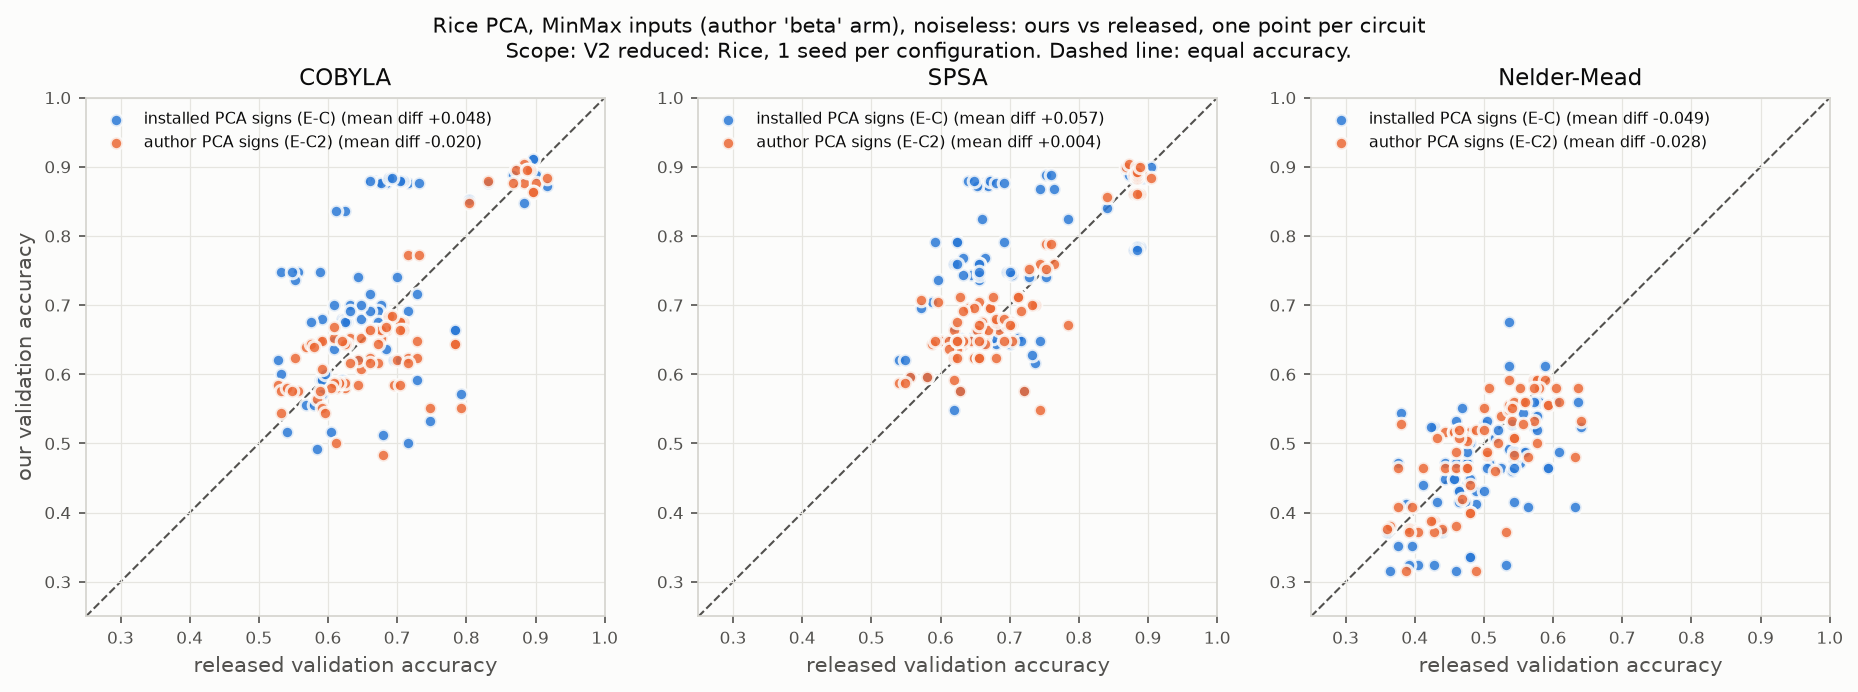

In [12]:
# STORED: agreement of our Rice re-runs with the released runs, paired by circuit.
# Source: results/*_agreement.csv, written by utils/analyze_sweeps.py from merlin-ai sweeps
# (code 861a180; E-C2 252/252 and E-D2 48/48 runs, 1 seed per circuit).
agreement = pd.concat(
    {
        "E-C2 noiseless": pd.read_csv(RESULTS / "E-C2_rice_grid_author_signs_agreement.csv"),
        "E-D2 FakePerth": pd.read_csv(RESULTS / "E-D2_rice_noisy_author_signs_agreement.csv"),
    }
).reset_index(level=0).rename(columns={"level_0": "sweep"})
agreement = agreement[agreement["init"] == "beta"]
display(agreement[["sweep", "optimizer", "n_pairs", "ours_mean", "released_mean", "mean_diff", "pearson", "replicate_pearson"]].round(3))
display(Image(filename=str(RESULTS / "E-C_vs_E-C2_minmax.png"), width=760))

**Observation.** Per circuit, our noiseless runs agree with the released ones:
- mean differences of -0.02 to +0.004;
- Pearson 0.84 / 0.88 for COBYLA / SPSA, about as high as the authors' own
  replicate runs agree with each other (0.78 / 0.86).

Under noise, the agreement is +0.004 / +0.003, with Pearson 0.96 / 0.99.
Nelder-Mead has no replicate to compare against (-0.028, Pearson 0.68).

**Inference.** The ported implementation reproduces the paper's per-run
numbers. Section 6's result is therefore not an artefact of a different
implementation.

**Remaining uncertainty.** One seed per circuit. Remaining offsets of
0.02-0.03 are within single-configuration run-to-run spread.

**Claim impact.** C8 (the top configurations) and C9 (the cost of noise) are
**reproduced**. The data behind C1 is reproduced, but its interpretation is not.

## 8. Fair baseline comparison

The paper claims no advantage over classical models, so the "paper baseline" for
C1 is internal: the uniform/normal arms. Section 3 showed it is **not a fair
control**, because it differs from the beta arm in input scaling. The fair
control is E-B (section 9).

For context, we also ask: on identical inputs, how does the QNN compare with
standard classifiers?

| Dimension | QNN (E-B) | Classical (E-F) | Photonic (E-P, adaptation) |
|---|---|---|---|
| Information / inputs | same rows, PCA-7 or LDA-5 features, MinMax | same | same |
| Parameter count | 20-56 | 8-570 across LR, SVM (support-vector coefficients) and MLP; the MLP is **matched** to the QNN: 28 (Rice), 30 (Glass) | 246-576, **not matched** |
| Training data | 400 rows (Glass 128) | same | same |
| Optimization steps | COBYLA <= 500 / SPSA 150 iterations | sklearn defaults; MLP a fixed 500 epochs (often reaches the cap) | Adam, 200 steps |
| Tuning budget | none beyond the grid | 5-fold CV grid on training rows only | none beyond the grid |
| Compute / wall time | 3-38 s per run, CPU | about 1-4 s per run, CPU | 51-105 s per run, shared L4 GPU |
| Evaluation protocol | choose on validation, report test | same | same |

"Matched" applies only to the MLP's parameter count. Everything else in the
table is identical across systems, or reported but not matched.

**LIVE.** Classical models on Rice MinMax, 3 seeds. The stored E-F sweep uses
10 seeds and all four datasets.

In [13]:
# LIVE: classical baselines on the same Rice MinMax rows (5-fold CV on train only).
data = rice["minmax"]
classical_rows = []
for model_name in ("logistic_regression", "rbf_svm", "mlp"):
    for seed in (1, 2, 3):
        out = fit_and_evaluate(model_name, data.X, data.y, parameter_target=28, seed=seed, cv_folds=5)
        classical_rows.append({"model": model_name, "seed": seed, "parameters": out["parameters"],
                               "val_accuracy": out["val"]["accuracy"], "test_accuracy": out["test"]["accuracy"]})
classical_live = pd.DataFrame(classical_rows)
classical_live.groupby("model")[["parameters", "val_accuracy", "test_accuracy"]].agg(["mean", "std"]).round(3)

parameters         val_accuracy        test_accuracy  \
                          mean     std         mean    std          mean   
model                                                                      
logistic_regression      8.000   0.000        0.916  0.000         0.916   
mlp                     28.000   0.000        0.913  0.002         0.908   
rbf_svm                 87.333  17.898        0.919  0.002         0.903   

                            
                       std  
model                       
logistic_regression  0.000  
mlp                  0.000  
rbf_svm              0.005

,data,system,selected_configuration,selected_runs,selected_val_mean,selected_test_mean,selected_test_sd,capacity_min,capacity_max
0,rice,qubit QNN (E-B),"init=beta, circuit=c57, optimizer=spsa",3,0.897,0.876,0.004,28,56
1,rice,classical (E-F),model=rbf_svm,10,0.918,0.901,0.005,8,237
2,rice,"photonic MerLin (E-P, adaptation)","init=default, photons=n4, depth=d2",3,0.920,0.885,0.006,394,576
6,glass,qubit QNN (E-B),"init=default, circuit=c31, optimizer=spsa",3,0.589,0.473,0.067,20,40
7,glass,classical (E-F),model=rbf_svm,10,0.642,0.567,0.012,30,520
8,glass,"photonic MerLin (E-P, adaptation)","init=beta, photons=n4, depth=d1",3,0.636,0.589,0.036,246,336


,data,qubit_capacity,mlp_capacity,qubit_runs,mlp_runs,qubit_test_mean,qubit_test_sd,mlp_test_mean,mlp_test_sd,mlp_minus_qubit,separation_threshold,separated
0,rice,28,28,3,10,0.876,0.004,0.908,0.004,0.032,0.008,True
1,glass,20,30,3,10,0.473,0.067,0.507,0.081,0.034,0.162,False


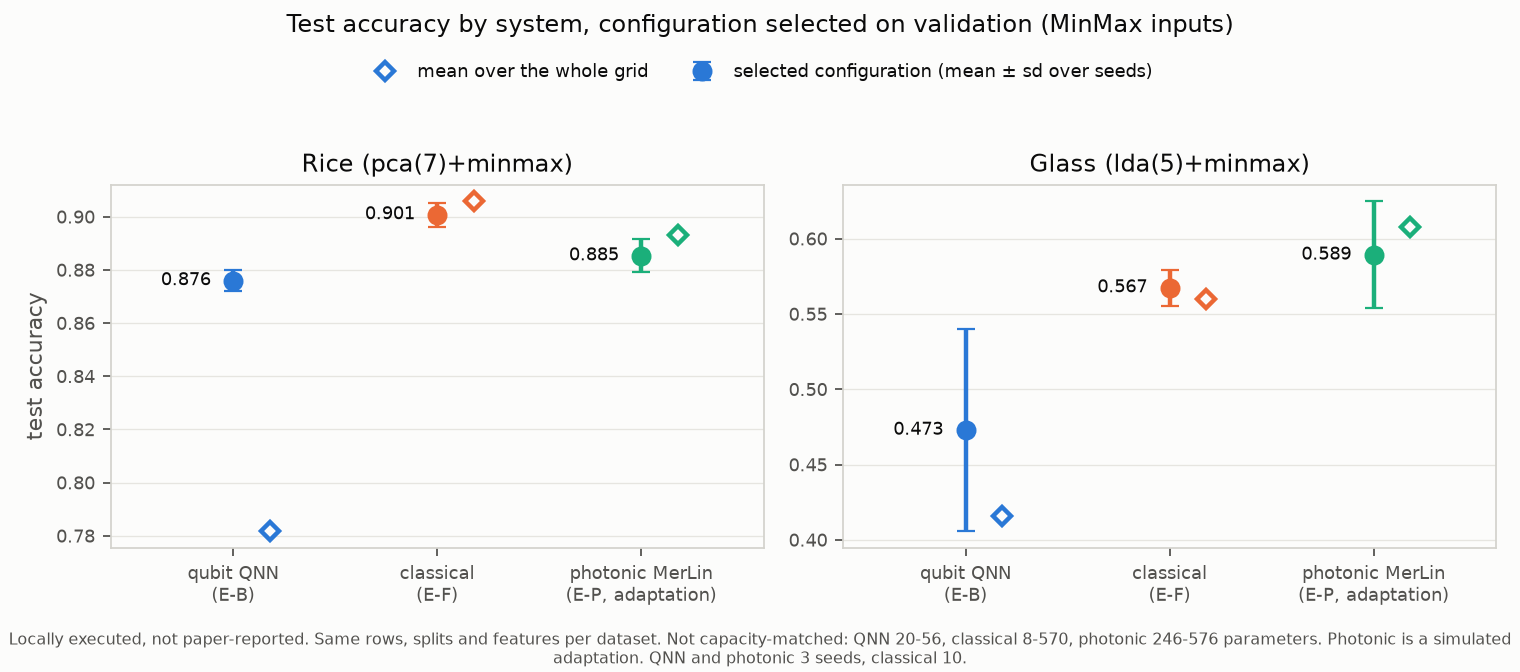

In [14]:
# STORED: the frozen Phase 5 comparison (configuration chosen on validation, test reported).
# Source: results/phase5_*.csv from utils/compare_systems.py over E-B (288), E-F (420) and E-P (144) runs,
# all on merlin-ai; recomputed independently by utils/recompute_check.py (max discrepancy 6.7e-16).
systems = pd.read_csv(RESULTS / "phase5_systems.csv").query("scaling == 'minmax'")
display(systems[["data", "system", "selected_configuration", "selected_runs", "selected_val_mean",
                 "selected_test_mean", "selected_test_sd", "capacity_min", "capacity_max"]].round(3))
display(pd.read_csv(RESULTS / "phase5_matched_capacity.csv").round(3))
display(Image(filename=str(RESULTS / "phase5_comparison.png"), width=820))

In [15]:
# STORED: does the comparison depend on which near-tied configuration is selected?
# Every candidate within one validation sample of each family's best is re-scored with the frozen separation rule.
sensitivity = pd.read_csv(RESULTS / "phase5_separation_sensitivity.csv")
sensitivity

,data,system_a,system_b,combinations,separated_a_higher,separated_b_higher,not_separated
0,rice,qubit QNN (E-B),classical (E-F),8,0,7,1
1,rice,qubit QNN (E-B),"photonic MerLin (E-P, adaptation)",20,0,7,13
2,rice,classical (E-F),"photonic MerLin (E-P, adaptation)",10,3,0,7
3,glass,qubit QNN (E-B),classical (E-F),4,0,2,2
4,glass,qubit QNN (E-B),"photonic MerLin (E-P, adaptation)",8,0,5,3
5,glass,classical (E-F),"photonic MerLin (E-P, adaptation)",8,0,3,5


**Observation.** On Rice:
- the parameter-matched MLP (28 parameters) reaches 0.908 ± 0.004 test
  accuracy, against 0.876 ± 0.004 for the validation-selected 28-parameter QNN;
- that separation holds in 7 of 8 near-tie combinations.

On Glass (43 test rows) nothing is separable. The photonic comparisons on both
datasets depend on which tied configuration is picked.

**Inference.** On identical inputs, the QNN does not beat a matched classical
model; on Rice it loses.

The live classical runs reproduce the stored ones for the same seeds. Logistic
regression, for example, picks C = 10 and scores 0.916 on seeds 1-3, both here
and on the server. The stored 10-seed logistic-regression mean is lower (0.909)
because cross-validation picks C = 1 on three of the other seeds.

**Remaining uncertainty.** Only Rice and Glass were compared on identical runs.
The photonic model is not capacity-matched.

**Claim impact.** No advantage is claimed by the paper, and none is observed.
The "best QNN" numbers in Tables 2-5 are matched or beaten by simple models.

## 9. Controls and ablations

**9a. The decisive control: E-B (STORED).** This is the full factorial:
- input scaling {raw, MinMax} x *applied* initialization {default, beta, zeros};
- 4 circuits x {COBYLA, SPSA} x 3 seeds, on Rice and Glass: 288 runs;
- paired Wilcoxon tests, Holm-corrected across the family.

,data,effect,comparison,n_pairs,mean_diff,ci95,holm_p
0,glass,scaling,minmax - raw | init=default,24,0.1579,"[0.11627906976744189, 0.19573643410852715]",0.0006
1,glass,scaling,minmax - raw | init=beta,24,0.1105,"[0.06589147286821705, 0.15988372093023254]",0.0033
2,glass,scaling,minmax - raw | init=zeros,24,0.1405,"[0.09205426356589146, 0.187984496124031]",0.0012
3,glass,init,beta - default | scaling=raw,24,0.0213,"[-0.008720930232558138, 0.049418604651162795]",1.0000
4,glass,init,zeros - default | scaling=raw,24,0.0087,"[-0.019379844961240313, 0.03682170542635659]",1.0000
5,glass,init,beta - default | scaling=minmax,24,-0.0262,"[-0.06395348837209303, 0.009689922480620153]",1.0000
6,glass,init,zeros - default | scaling=minmax,24,-0.0087,"[-0.04265988372093025, 0.025193798449612396]",1.0000
7,rice,scaling,minmax - raw | init=default,24,0.3137,"[0.26099999999999995, 0.3603333333333334]",0.0003
8,rice,scaling,minmax - raw | init=beta,24,0.3052,"[0.24833333333333332, 0.3550041666666666]",0.0003
9,rice,scaling,minmax - raw | init=zeros,24,0.3087,"[0.2511666666666667, 0.3613374999999999]",0.0003


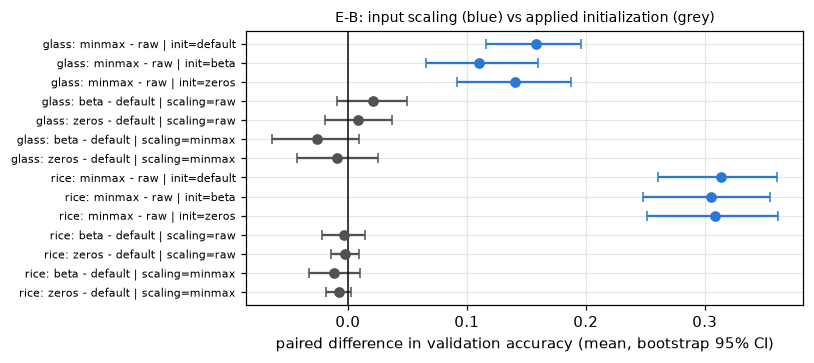

In [16]:
# STORED: E-B paired effects. Source: results/E-B_mechanism_effects_val.csv
# (merlin-ai, 288/288 runs; clean-commit rerun at 861a180 gave identical tables).
effects = pd.read_csv(RESULTS / "E-B_mechanism_effects_val.csv")
display(effects[["data", "effect", "comparison", "n_pairs", "mean_diff", "ci95", "holm_p"]].round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for row_index, row in enumerate(effects.itertuples()):
    low, high = json.loads(row.ci95)
    color = COLORS["qubit"] if row.effect == "scaling" else "#52514e"
    ax.errorbar(row.mean_diff, row_index, xerr=[[row.mean_diff - low], [high - row.mean_diff]], fmt="o", color=color, capsize=3)
ax.set_yticks(range(len(effects)), [f"{r.data}: {r.comparison}" for r in effects.itertuples()], fontsize=7)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlabel("paired difference in validation accuracy (mean, bootstrap 95% CI)")
ax.set_title("E-B: input scaling (blue) vs applied initialization (grey)", fontsize=9)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Observation.**
- **Scaling:** MinMax minus raw is +0.31 on Rice and +0.11 to +0.16 on Glass,
  at every initialization (Holm $p \le 0.004$).
- **Initialization:** every applied-initialization effect at a fixed scaling
  lies within ±0.03 (-0.026 to +0.021), with Holm $p = 1.0$.

**Inference.** The paper's beta advantage is reproduced in size by input
scaling alone, and is *not* produced by applying a beta initialization. C1 is
refuted as stated.

**9b. Equivalence classes in the released data (LIVE).** If only the input
range matters, the six released initialization arms should form two groups:
- {uniform, normal, zero}: raw inputs;
- {beta, beta_mu, normal_beta}: MinMax inputs.

Within each group they should be equivalent, and across groups they should
differ.

In [17]:
# LIVE: paired TOST equivalence (+-0.02) between every pair of released initialization arms (~15 s).
equivalence = pd.DataFrame(reanalysis.init_equivalence(released, margin=0.02))
grouped = equivalence.groupby("same_input_scaling").agg(
    pairs=("pair", "count"), equivalent=("tost_equivalent", "sum"), mean_abs_diff=("mean_diff", lambda v: v.abs().mean()))
grouped.index = grouped.index.map({True: "same input scaling", False: "different input scaling"})
grouped.round(3)

,pairs,equivalent,mean_abs_diff
same_input_scaling,,,
different input scaling,36,0,0.167
same input scaling,24,24,0.004


**Observation.**
- All 24 within-group pairs are equivalent within ±0.02 (mean |difference|
  0.004).
- None of the 36 across-group pairs is equivalent (mean |difference| 0.167).

**Inference.** This is exactly what an unapplied initialization plus a scaling
difference predicts. It also explains C3: beta, beta_mu and normal_beta "do not
differ" because they are the same procedure.

**9c. Ablation: PCA sign convention (STORED).** Our first noiseless re-run (E-C)
used scikit-learn's current PCA signs, and disagreed with the released MinMax
arm by +0.05. E-C2 differs only in restoring the author's scikit-learn 1.2.2
sign convention.

In [18]:
# STORED: E-C (installed signs) vs E-C2 (author signs), MinMax arm. Sources: results/E-C*_agreement.csv.
signs = pd.concat({
    "installed signs (E-C)": pd.read_csv(RESULTS / "E-C_rice_grid_agreement.csv"),
    "author signs (E-C2)": pd.read_csv(RESULTS / "E-C2_rice_grid_author_signs_agreement.csv"),
}).reset_index(level=0).rename(columns={"level_0": "PCA signs"})
signs[signs["init"] == "beta"].pivot_table(index="optimizer", columns="PCA signs", values=["mean_diff", "pearson"]).round(3)

mean_diff                                   pearson  \
PCA signs  author signs (E-C2) installed signs (E-C) author signs (E-C2)   
optimizer                                                                  
cobyla                  -0.020                 0.048               0.836   
neldermead              -0.028                -0.049               0.681   
spsa                     0.004                 0.057               0.882   

                                  
PCA signs  installed signs (E-C)  
optimizer                         
cobyla                     0.569  
neldermead                 0.611  
spsa                       0.514

**Observation.** With the author's sign convention:
- the MinMax-arm offsets shrink, for COBYLA / SPSA / Nelder-Mead, from +0.048 /
  +0.057 / -0.049 to -0.020 / +0.004 / -0.028;
- per-circuit correlation rises from 0.51-0.61 to 0.68-0.88.

The raw arm was unaffected (not shown; within ±0.002).

**Inference.** Flipping a PCA component changes the encoded *angle*, not just a
label, so angle-encoded models are sensitive to a scikit-learn version change.
This was a reproduction gap, not a property of the method.

**Claim impact.** None on C1-C9. It explains the only large discrepancy we met.

## 10. Robustness and uncertainty

| Source of uncertainty | Size | Where it matters |
|---|---|---|
| Seed variation, QNN (3 seeds) | test sd 0.004 (Rice) to 0.067 (Glass) | Glass comparisons are not separable |
| Small data (Glass) | 1 sample = 0.023 accuracy; 43 val / 43 test rows | All Glass conclusions |
| Unseeded noisy simulator (E-D, E-D2; the author's code was unseeded too) | single configurations move up to 0.1 between identical runs; aggregate agreement within 0.015 | Noise results (C9) are aggregate-only |
| GPU non-determinism (photonic E-P) | identical seeds moved effects up to 0.03 | Cite photonic significance patterns, not exact sizes |
| Validation selection ties (Phase 5) | Glass photonic top two tie exactly | Only "classical > QNN on Rice" is robust |
| Code provenance | E-B, E-C, E-C2, E-D, E-F reproduced at clean commit 861a180; E-P verdicts reproduced, not its sizes; E-D2 not rerun | Accepted, documented limitation |

The live cells in sections 6 and 8 are an independent check of the stored
results: different hardware, run today, same code. Section 6 reproduces the
E-B pattern on its circuit: raw near chance, MinMax near 0.9, and no gain from
an applied initialization. Section 8 reproduces the E-F classical runs seed for
seed.

In [19]:
# Live vs stored: E-B cell means for the same circuit family on Rice (stored = 4 circuits x 2 optimizers x 3 seeds).
stored_cells = pd.read_csv(RESULTS / "E-B_mechanism_cell_means_val.csv").query("data == 'rice'")
stored_cells = stored_cells.assign(init=stored_cells["init"].replace({"default": "qiskit_default"}))
comparison = live.groupby(["scaling", "init"])["val_accuracy"].agg(live_mean="mean", live_sd="std").join(
    stored_cells.set_index(["scaling", "init"])[["mean", "sd"]].rename(columns={"mean": "stored_E-B_mean", "sd": "stored_E-B_sd"}))
comparison.round(3)

live_mean  live_sd  stored_E-B_mean  stored_E-B_sd
scaling init                                                              
minmax  beta                0.856    0.028            0.813          0.130
        qiskit_default      0.893    0.006            0.824          0.115
        zeros               0.904    0.004            0.817          0.126
raw     beta                0.496    0.031            0.508          0.037
        qiskit_default      0.485    0.023            0.511          0.027
        zeros               0.477    0.032            0.509          0.033

**Observation.**
- **MinMax cells:** the live single-circuit COBYLA cells (0.86-0.90) sit above
  the stored E-B means (0.81-0.82). The stored means average four circuits and
  two optimizers, including weaker ones (their sd is about 0.12), so this is
  expected.
- **Raw cells:** near chance in both (live 0.48-0.50, stored about 0.51).
- **Pattern:** the same. Scaling separates the cells; initialization does not.

**Claim impact.** The conclusions above are robust to seed, hardware and run
date. Only the Glass comparisons and the photonic effect *sizes* remain
uncertain.

## 11. Photonic (MerLin) adaptation

**Status: `PARTIAL_MERLIN_TRANSLATION`, an adaptation, not a reproduction.** We
translate the paper's *question* (does input scaling or initialization drive
accuracy?), not its qubit circuits:
- A trainable MZI mesh is universal on its modes, so ansatz-family and
  entanglement choices (C4, C5) have no photonic counterpart.
- Photon number and data-reuploading depth stand in for the architecture
  factors.

**Model** (`lib/photonic.py`, MerLin 0.4.1):
- $2d$ optical modes for $d$ features, and $n \in \{2, 4\}$ photons.
- A trainable mesh, then `depth` x [phase shift $\pi x_i$ on mode $2i$, then a
  trainable mesh].
- Readout: the expected photon count in each mode (`mode_expectations`,
  threshold detection, `ComputationSpace.UNBUNCHED`, no postselection), fed to a
  linear head.
- Training: Adam on exact gradients.

**Hardware assumptions:** simulator only; exact expectations (no shots); no
photon loss; perfect indistinguishability. Two MerLin issues found here are
written up for the MerLin team: a CUDA device bug in the readout mask, and a
missing Perceval version cap.

**LIVE known-answer check and a short training demo** on Glass (10 modes, 2
photons):
- The per-mode photon expectations must sum to the photon number.
- Then 100 Adam steps on raw vs MinMax inputs (E-P used 200 steps; this is a
  labelled reduction, about 75 s).

In [20]:
# LIVE: photonic model on Glass, CPU.
import torch
from QNN_hyperparameters.lib.photonic import PhotonicClassifier

glass = {scaling: prepare_data(rice_config(scaling, dataset={"name": "glass", "preprocessing": "lda"})) for scaling in ("raw", "minmax")}
torch.manual_seed(1)
probe = PhotonicClassifier({"init": "merlin_default"}, {"photons": 2, "depth": 1}, glass["minmax"].n_features, "cpu", np.random.default_rng(1))
expectations = probe.layer(torch.as_tensor(glass["minmax"].X["train"][:8], dtype=probe.phases.dtype))
print(f"modes {probe.n_modes}, photons {probe.n_photons}, input state {probe.input_state}, trainable phases {probe.num_phases}")
print("sum of per-mode expectations per sample:", expectations.sum(dim=1).detach().numpy().round(6))
assert torch.allclose(expectations.sum(dim=1), torch.full((8,), 2.0, dtype=expectations.dtype), atol=1e-6)
print("PASS: photon number is conserved by the simulated interferometer")

photonic_rows = []
start_time = time.time()
for scaling, data in glass.items():
    torch.manual_seed(1)
    model = PhotonicClassifier({"init": "merlin_default"}, {"photons": 2, "depth": 1}, data.n_features, "cpu", np.random.default_rng(1))
    result = model.fit(data.X["train"], data.y["train"], {"optimizer": "Adam", "steps": 100, "lr": 0.05})
    photonic_rows.append({"scaling": scaling, "steps": 100, "final_loss": result.losses[-1],
                          "val_accuracy": model.evaluate(data.X["val"], data.y["val"])["accuracy"]})
print(f"2 photonic runs in {time.time() - start_time:.0f} s")
pd.DataFrame(photonic_rows).round(3)

modes 10, photons 2, input state [1, 0, 0, 0, 0, 1, 0, 0, 0, 0], trainable phases 180
sum of per-mode expectations per sample: [2. 2. 2. 2. 2. 2. 2. 2.]
PASS: photon number is conserved by the simulated interferometer


2 photonic runs in 38 s


,scaling,steps,final_loss,val_accuracy
0,raw,100,1.003,0.442
1,minmax,100,0.750,0.628


In [21]:
# STORED: the full E-P sweep (144 runs: data x scaling x init x photons {2,4} x depth {1,2} x 3 seeds),
# merlin-ai NVIDIA L4, exact expectations. Source: results/E-P_photonic_mechanism_*.csv.
photonic_cells = pd.read_csv(RESULTS / "E-P_photonic_mechanism_cell_means_val.csv")
display(photonic_cells.pivot_table(index=["data", "scaling"], columns="init", values="mean").round(3))
photonic_effects = pd.read_csv(RESULTS / "E-P_photonic_mechanism_effects_val.csv")
display(photonic_effects[["data", "effect", "comparison", "n_pairs", "mean_diff", "holm_p"]].round(4))

init            beta  default  zeros
data  scaling                       
glass minmax   0.612    0.595  0.599
      raw      0.465    0.461  0.432
rice  minmax   0.903    0.917  0.912
      raw      0.531    0.532  0.535

,data,effect,comparison,n_pairs,mean_diff,holm_p
0,glass,scaling,minmax - raw | init=default,12,0.1337,0.0068
1,glass,scaling,minmax - raw | init=beta,12,0.1473,0.0068
2,glass,scaling,minmax - raw | init=zeros,12,0.1667,0.0068
3,glass,init,beta - default | scaling=raw,12,0.0039,1.0000
4,glass,init,zeros - default | scaling=raw,12,-0.0291,1.0000
5,glass,init,beta - default | scaling=minmax,12,0.0174,1.0000
6,glass,init,zeros - default | scaling=minmax,12,0.0039,1.0000
7,rice,scaling,minmax - raw | init=default,12,0.3843,0.0068
8,rice,scaling,minmax - raw | init=beta,12,0.3720,0.0068
9,rice,scaling,minmax - raw | init=zeros,12,0.3770,0.0068


**Observation.**
- **Live:** in the short run, MinMax inputs train to a higher validation
  accuracy than raw inputs. This is one seed and 100 steps, so it is an
  illustration only.
- **Stored sweep, scaling:** MinMax minus raw is +0.37 to +0.38 on Rice and
  +0.13 to +0.17 on Glass (Holm $p = 0.007$, the smallest possible with 12
  pairs).
- **Stored sweep, everything else:** no initialization, photon-number or depth
  effect is significant.

**Inference.** The photonic classifier shows the same mechanism as the qubit
model: phase-encoded inputs must be scaled into a range where the encoding
does not wrap, and the initial phases do not matter. This met the preservation
rule fixed before the sweep ran.

**Remaining uncertainty.**
- Simulator only, with no shots and no loss.
- About 10 times the QNN's parameters.
- A same-seed GPU rerun moved effect sizes by up to 0.03, but kept every
  verdict.

**Claim impact (on the adaptation).** The mechanism is preserved. There is no
photonic advantage over matched classical models (section 8).

## 12. Claim-level conclusion

**Separate outcomes:**

| Question | Answer | Evidence |
|---|---|---|
| Does the software execute? | Yes: every live cell runs on CPU; the full sweeps completed (1,704 runs). | All sections |
| Does the method solve the task? | Yes, with MinMax inputs: about 0.88 test accuracy on Rice. With raw inputs it stays near chance. | §6, §8 |
| Do the paper's metrics reproduce? | Yes: Tables 2-5, noise costs and Table 7 from the released files; per-circuit re-runs within the authors' replicate spread. | §7 |
| Does the paper's explanation survive controls? | **No** for C1: the gain is input scaling; an applied beta initialization does nothing. | §3, §4, §6, §9 |
| Does the method beat a fair baseline? | No: a parameter-matched MLP beats the QNN on Rice, and nothing is separable on Glass. The paper does not claim otherwise. | §8 |

**1. What reproduced**
- The released results: Tables 2-5 best F1, noise costs, and the Table 7
  statistics (§7a).
- Per-circuit Rice re-runs, noiseless and FakePerth (§7b).
- C2, the optimizer ranking at the executed budgets.
- C4, no ansatz effect (see `README.md`).

**2. What did not reproduce**
- C1 as stated. "Beta initialization" is an input-scaling effect, and the
  initialization is never applied in the author code (§3, §4, §6, §9a).

**3. What remains unresolved**
- C2 at equal cost: the budgets in the author code are swapped and unequal
  (§8, `README.md`).
- Every Glass system comparison (§8, §10).
- Photonic effect sizes beyond their significance pattern (§10, §11).

**4. What was not attempted**
- Full re-training of the KDD and Cover Type grids (about 10,000 runs). They
  are covered by re-analysing the released results.
- The live `ibm_perth` noise model.
- An equal-evaluation optimizer comparison.
- Shot-based or lossy photonic runs.
- A capacity-matched photonic model.

**5. Reproduction verdict: partially reproduced.**
- The numbers are reproduced.
- The central claim C1 is **contradicted** by a controlled experiment.
- C3 holds only in a re-attributed form: the "range that matters" is the
  *input* range.

**6. Photonic verdict:**
- **Status:** `PARTIAL_MERLIN_TRANSLATION`.
- **Mechanism:** preserved (input scaling matters; initialization, photon
  number and depth do not).
- **Advantage:** none observed over matched classical models.
- **Scope:** simulator-only (§11).

### Limitations

- **Reduced live runs:** sections 6, 8 and 11 run 1 circuit, 3 seeds, or 100
  photonic steps live. The decisive evidence is the stored full sweeps, loaded
  with their provenance.
- **Re-training scope:** Rice (grids) and Rice + Glass (mechanism). The other
  datasets are covered from released results only.
- **One seed per circuit** in the grid re-runs (E-C, E-C2, E-D, E-D2).
- **Software port:** Qiskit 1.4 instead of 0.42, checked to $10^{-10}$ (§4); the
  author PCA signs had to be restored (§9c).
- **Noise and provenance:**
  - noisy runs are unseeded;
  - E-D2 was not rerun at the clean commit;
  - E-P reproduced its verdicts but not its exact sizes (§10).
- **Photonic:** simulator only, not capacity-matched.

In [22]:
print(f"notebook executed in {time.time() - NOTEBOOK_START:.0f} s on CPU")

notebook executed in 414 s on CPU
